# 调优前后最终测试结果对比

在 `RUN_PAIRS` 中手动指定“调优前最终测试目录 → 调优后最终测试目录”，默认包含 AAPL 和 TSLA。选择 **EE6008 → Restart Kernel → Run All**。

结。

## 1. 调优前后最终测试结果表格

每只股票一张表，`前 → 后` 表示调优前后模型在完整测试期上的结果。请选用已核验、测试日期与任务一致的实验。

- **MAE / RMSE** 越低越好，以收益百分点（pp）展示；**R² / R² vs zero** 越高越好。
- **RMSE 改善率** = `(原 RMSE − 新 RMSE) / 原 RMSE × 100%`。
- **方向准确率改善率** = `(新准确率 − 原准确率) / 原准确率 × 100%`，正数表示改善；原值为零时显示 `N/A`。
- 例如准确率从 50% 升至 55%，相对改善率为 **10%**，而柱状图中的变化为 **+5 个百分点**。
- 上涨 F1 需结合预测上涨比例阅读。这里归档已完成的最终测试，不根据这些分数继续选择超参数。

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'main.py').is_file() and (p / 'src/evaluate.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('请从 stock_prediction 或 notebooks 目录打开此 Notebook')
# 每一对为（调优前最终测试目录，调优后最终测试目录），只写 artifacts 下的目录名。
# 不根据目录名判断股票；未来加入其他股票时可增加一对目录。
RUN_PAIRS = [
    ('aapl_final_test_01', 'aapl_final_test_02'),
    ('tsla_final_test_01', 'tsla_final_test_02'),
]
MODELS = ['xgboost', 'lightgbm', 'patchtst', 'lstm', 'gru']
BASELINES = ['zero_return', 'historical_mean', 'last_return']
LABELS = dict(zip(MODELS + BASELINES,
                 ['XGBoost', 'LightGBM', 'PatchTST', 'LSTM', 'GRU',
                  'Zero return', 'Historical mean', 'Last return']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

In [2]:
def load_run(name):
    if not isinstance(name, str) or re.fullmatch(r'[A-Za-z0-9_-]+', name) is None:
        raise ValueError('只填写 artifacts 下的实验目录名')
    folder = ROOT / 'artifacts' / name
    run = {'name': name, **{key: json.loads((folder / f'{key}.json').read_text(encoding='utf-8-sig'))
                           for key in ['config', 'metrics', 'manifest']}}
    # 仅防止误选验证目录或未完成结果；不重复校验数据指纹、配置或逐日预测。
    if run['manifest'].get('status') != 'complete' or run['manifest'].get('evaluation_split') != 'test':
        raise ValueError(f'{name} 不是已完成的最终测试结果')
    return run


if not RUN_PAIRS:
    raise ValueError('请在 RUN_PAIRS 指定调优前后的最终测试目录')
pairs = []
for before_name, after_name in RUN_PAIRS:
    before, after = load_run(before_name), load_run(after_name)
    ticker = before['config']['ticker']
    if after['config']['ticker'] != ticker:
        raise ValueError('每对目录必须属于同一只股票')
    pairs.append((ticker, before, after))
    print(f'{ticker}: {before_name} → {after_name}')
    print(f"  模型来源：{before['manifest'].get('source_run', '未记录')} → {after['manifest'].get('source_run', '未记录')}")

AAPL: aapl_final_test_01 → aapl_final_test_02
  模型来源：aapl_compare_all_01 → aapl_compare_all_02
TSLA: tsla_final_test_01 → tsla_final_test_02
  模型来源：tsla_compare_all_01 → tsla_compare_all_02


In [3]:
metric_keys = ['mae', 'rmse', 'r2', 'r2_vs_zero', 'direction_accuracy', 'up_f1', 'predicted_up_rate']
records = []
for ticker, before, after in pairs:
    for model in MODELS:
        old, new = before['metrics'][model], after['metrics'][model]
        row = {'stock': ticker, 'model': model, 'before_run': before['name'], 'after_run': after['name']}
        for metric in metric_keys:
            row[metric + '_before'], row[metric + '_after'] = old[metric], new[metric]
        row['rmse_improvement_pct'] = 100*(1-new['rmse']/old['rmse']) if old['rmse'] else np.nan
        row['direction_improvement_pct'] = (100*(new['direction_accuracy']/old['direction_accuracy']-1)
                                             if old['direction_accuracy'] else np.nan)
        # 柱状图使用百分点差值；表格使用相对改善率，两者单位不同。
        row['direction_change_pp'] = 100*(new['direction_accuracy']-old['direction_accuracy'])
        records.append(row)
comparison = pd.DataFrame(records)
for ticker, before, after in pairs:
    display(Markdown(f'### {ticker}'))
    rows = comparison.loc[(comparison.before_run == before['name']) & (comparison.after_run == after['name'])]
    table = pd.DataFrame(index=[LABELS[m] for m in rows.model])
    table.index.name = 'Model'
    for metric, title, scale, digits in [
        ('mae', 'MAE (pp)', 100, 4),
        ('rmse', 'RMSE (pp)', 100, 4),
        ('r2', 'R²', 1, 4),
        ('r2_vs_zero', 'R² vs zero', 1, 4),
        ('direction_accuracy', '方向准确率 (%)', 100, 2),
        ('up_f1', 'Up F1', 1, 4),
        ('predicted_up_rate', '预测上涨 (%)', 100, 2),
    ]:
        table[title] = [f"{r[metric + '_before'] * scale:.{digits}f} → {r[metric + '_after'] * scale:.{digits}f}"
                        for _, r in rows.iterrows()]
    for key, title in [('rmse_improvement_pct', 'RMSE 改善率 (%)'),
                       ('direction_improvement_pct', '方向准确率改善率 (%)')]:
        table[title] = [f'{v:+.2f}' if pd.notna(v) else 'N/A' for v in rows[key]]
    display(table)

### AAPL

,MAE (pp),RMSE (pp),R²,R² vs zero,方向准确率 (%),Up F1,预测上涨 (%),RMSE 改善率 (%),方向准确率改善率 (%)
Model,,,,,,,,,
XGBoost,1.1692 → 1.1663,1.7745 → 1.7696,-0.0161 → -0.0105,-0.0138 → -0.0082,52.79 → 52.79,0.6731 → 0.6784,90.04 → 92.43,+0.28,+0.00
LightGBM,1.1547 → 1.1723,1.7636 → 1.7842,-0.0036 → -0.0272,-0.0013 → -0.0248,54.18 → 55.18,0.6958 → 0.6647,96.22 → 79.28,-1.17,+1.84
PatchTST,1.2626 → 1.2623,1.8375 → 1.8372,-0.0895 → -0.0892,-0.0870 → -0.0867,49.60 → 49.60,0.5600 → 0.5600,60.16 → 60.16,+0.02,+0.00
LSTM,1.1561 → 1.1437,1.7596 → 1.7030,0.0009 → 0.0642,0.0032 → 0.0663,54.38 → 51.99,0.7045 → 0.6181,100.00 → 71.31,+3.22,-4.40
GRU,1.1576 → 1.1596,1.7587 → 1.7587,0.0019 → 0.0019,0.0042 → 0.0042,53.19 → 52.39,0.6904 → 0.6739,96.81 → 91.63,+0.00,-1.50


### TSLA

,MAE (pp),RMSE (pp),R²,R² vs zero,方向准确率 (%),Up F1,预测上涨 (%),RMSE 改善率 (%),方向准确率改善率 (%)
Model,,,,,,,,,
XGBoost,2.8951 → 2.9056,3.9920 → 3.9935,0.0002 → -0.0006,0.0026 → 0.0019,50.60 → 50.40,0.6242 → 0.6054,81.08 → 75.30,-0.04,-0.39
LightGBM,2.9046 → 2.9446,4.0008 → 4.0468,-0.0042 → -0.0275,-0.0018 → -0.0250,50.20 → 51.99,0.6575 → 0.5922,95.02 → 67.33,-1.15,+3.57
PatchTST,3.0629 → 3.0624,4.1632 → 4.1627,-0.0874 → -0.0872,-0.0848 → -0.0845,47.61 → 47.61,0.4368 → 0.4368,42.63 → 42.63,+0.01,+0.00
LSTM,2.8938 → 2.9149,3.9948 → 4.0260,-0.0012 → -0.0169,0.0012 → -0.0145,50.40 → 49.40,0.6702 → 0.5753,100.00 → 68.73,-0.78,-1.98
GRU,2.8980 → 2.9011,3.9989 → 4.0041,-0.0033 → -0.0059,-0.0008 → -0.0035,51.39 → 47.61,0.6703 → 0.6237,97.01 → 88.84,-0.13,-7.36


## 2. 变化幅度柱状图

每行一只股票：左侧为 **RMSE 相对改善率（%）**，右侧为**方向准确率变化（百分点）**。
向右为改善，向左为下降；两个面板单位不同，不直接比较柱长。

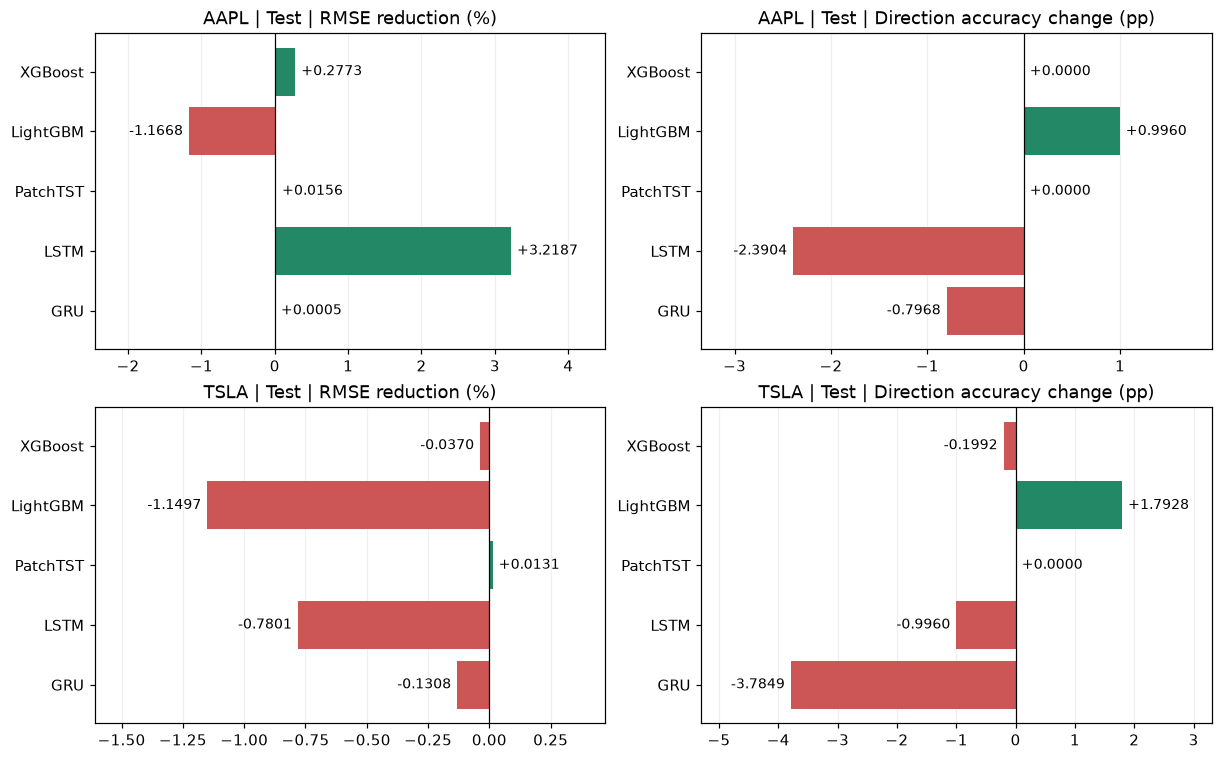

In [4]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(11, 3.4*len(pairs)),
                         squeeze=False, layout='constrained')
specs = [('rmse_improvement_pct','RMSE reduction (%)'),
         ('direction_change_pp','Direction accuracy change (pp)')]
for i, (ticker, before, after) in enumerate(pairs):
    data = comparison.loc[(comparison.before_run == before['name']) &
                          (comparison.after_run == after['name'])].set_index('model').loc[MODELS]
    for j, (metric, label) in enumerate(specs):
        ax = axes[i,j]
        values = data[metric].to_numpy(dtype=float)
        colors = ['#228866' if v > 1e-12 else '#CC5555' if v < -1e-12 else '#888888' for v in values]
        bars = ax.barh([LABELS[m] for m in MODELS], values, color=colors)
        ax.bar_label(bars, labels=[f'{v:+.4f}' for v in values], padding=4, fontsize=9)
        ax.axvline(0, color='black', linewidth=.8)
        span = max(float(np.nanmax(np.abs(values))), .001)
        ax.set_xlim(min(0,float(np.nanmin(values)))-.4*span,
                    max(0,float(np.nanmax(values)))+.4*span)
        ax.invert_yaxis()
        ax.set_title(f'{ticker} | Test | {label}')
        ax.grid(axis='x', alpha=.2)
        ax.set_axisbelow(True)
plt.show()
plt.close(fig)